# Fast adaptive retraining for MZI mesh



In [1]:
from pathlib import Path
from utils.datasets import flat_result_path, flat_result_directory
import json, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from utils.datasets import load_fmnist, save_json
from utils.preprocessing import split_fmnist_for_mzi
from utils.mzi_training import (train_source, distill_coreset, evaluate_main,
    evaluate_random_extension, load_source)
from utils.plotting import COLORS, publication_style, export_figure

%matplotlib inline
ROOT = Path.cwd()
DOWNLOAD_DATA = False
SAVE_FIGURES = False  # Figures remain visible; enable to export files.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(2)

RERUN = ROOT / 'results/simulation' / 'mzi'
RESULTS = RERUN
FIGURES = ROOT / 'results/simulation/mzi/figures' / ('recomputed')
for folder in [RERUN, FIGURES]:
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)
source_path = (RERUN) / 'source.pt'
coreset_path = (RERUN) / 'coreset.pt'
print('Train, distill and evaluate from Fashion-MNIST.')


Train, distill and evaluate from Fashion-MNIST.


## 1. Data and configuration


In [2]:
config = {
    'dataset': 'FashionMNIST', 'split_seed': 20260926, 'modes': 64, 'layers': 2,
    'errors': {'sph': 0.05, 'sbs': 0.03, 'loss_db': 0.1, 'loss_sd': 0.02},
    'source': {'seed': 7401, 'power': 0.25, 'epochs': 60, 'batch': 256, 'lr': 0.02},
    'distillation': {'seed': 7402, 'inner_lr': 0.001, 'data_lr': 0.01,
        'rule_lr': 0.003, 'momentum_lr': 0.001, 'outer': 2500,
        'M': 80, 'B': 10, 'K': 8, 'chips_per_step': 4, 'query_batch': 1024,
        'validation_interval': 100, 'input_constraint': 'none'},
    'training_chip_pool': [300000, 316383],
    'validation_chips': list(range(4000, 4032)),
    'test_chips': list(range(2200000, 2200064)), 'chip_batch': 8,
    'baselines': {
        'fresh10': {'kind': 'stream', 'B': 10, 'K': 8, 'seeds': [7600, 7601, 7602],
            'recipe': {'opt': 'adam', 'momentum': 0.9, 'lr': 0.003}},
        'fresh10_long': {'kind': 'stream', 'B': 10, 'K': 128, 'seeds': [7600, 7601, 7602],
            'recipe': {'opt': 'adam', 'momentum': 0.9, 'lr': 0.001, 'decay': 1.0}},
        'full256_long': {'kind': 'stream', 'B': 256, 'K': 100, 'seeds': [7700, 7701, 7702],
            'recipe': {'opt': 'adam', 'momentum': 0.9, 'lr': 0.002, 'decay': 1.0}},
    },
    'extended_checks': [8, 16, 32, 64, 100, 128, 160, 192, 224, 256, 288, 320, 352, 384,
        388, 392, 396, 400, 404, 408, 412, 416, 420, 424, 428, 432, 436, 440, 444, 448,
        480, 512, 576, 640, 704, 768, 832, 896, 960, 1024],
    'dd_lr_scale': 1.0,
}

display(pd.DataFrame([
    {'Setting': 'Optical modes / layers', 'Value': f"{config['modes']} / {config['layers']}"},
    {'Setting': 'Synthetic inputs / batch / updates', 'Value': '80 / 10 / 8'},
    {'Setting': 'Validation / test chips', 'Value': f"{len(config['validation_chips'])} / {len(config['test_chips'])}"},
    {'Setting': 'Fabrication errors', 'Value': str(config['errors'])},
]))
dataset = None
data = load_fmnist(ROOT / 'dataset', device=DEVICE, download=DOWNLOAD_DATA)
dataset = split_fmnist_for_mzi(data, seed=config['split_seed'])
del data
print('Train / validation / test:', [len(labels) for _, labels in dataset])
save_json(RERUN / 'config.json', config)

,Setting,Value
0,Optical modes / layers,64 / 2
1,Synthetic inputs / batch / updates,80 / 10 / 8
2,Validation / test chips,32 / 64
3,Fabrication errors,"{'sph': 0.05, 'sbs': 0.03, 'loss_db': 0.1, 'lo..."


Train / validation / test: [55000, 5000, 10000]


## 2. Train the ideal source network

`PCA64 → MZI mesh → |E|² → power normalization / amplitude remodulation →
MZI mesh → |E|² → power normalization → electronic linear head`.



In [3]:
started = time.monotonic()
train_source(dataset, config, source_path)
print(f'Source training completed in {(time.monotonic() - started) / 60:.2f} min.')
source, encoder, network = load_source(source_path, DEVICE)
print(f"Source: epoch {source['best_epoch']}, validation {100 * source['val']:.4f}%")
print('MZIs per layer:', network.geo.n, '| Optical phases:', 2 * network.L * network.geo.n)

Source epoch 1/60: validation=79.0600%


Source epoch 2/60: validation=82.9000%


Source epoch 3/60: validation=81.9600%


Source epoch 4/60: validation=81.8800%


Source epoch 5/60: validation=79.0200%


Source epoch 6/60: validation=80.8400%


... (50 outputs left out)

Source epoch 57/60: validation=88.4200%


Source epoch 58/60: validation=88.4800%


Source epoch 59/60: validation=88.5600%


Source epoch 60/60: validation=88.4800%
Source training completed in 4.52 min.
Source: epoch 59, validation 88.5600%
MZIs per layer: 2016 | Optical phases: 8064


## 3. Distill the calibration inputs and update rule



In [4]:
started = time.monotonic()
distill_coreset(dataset, source_path, config, coreset_path)
print(f'Distillation completed in {(time.monotonic() - started) / 60:.2f} min.')
coreset = torch.load(flat_result_path(coreset_path), map_location=DEVICE, weights_only=True)
assert coreset.get('input_constraint', 'none') == 'none', 'Use the original signed-input coreset here.'
print(f"Coreset: outer step {coreset['completed_outer']}, validation {100 * coreset['best_dev']:.4f}%")
print('Inputs:', tuple(coreset['u'].shape), '| Targets:', tuple(coreset['t'].shape))

Distillation 0/2500: validation=78.9969%, best=78.9969%


Distillation 100/2500: validation=82.6356%, best=82.6356%


Distillation 200/2500: validation=83.7712%, best=83.7712%


Distillation 300/2500: validation=84.1575%, best=84.1575%


Distillation 400/2500: validation=84.6125%, best=84.6125%


Distillation 500/2500: validation=84.4219%, best=84.6125%


... (16 outputs left out)

Distillation 2200/2500: validation=85.7200%, best=85.7200%


Distillation 2300/2500: validation=85.7225%, best=85.7225%


Distillation 2400/2500: validation=85.7256%, best=85.7256%


Distillation 2500/2500: validation=85.7256%, best=85.7256%
Distillation completed in 21.70 min.
Coreset: outer step 2400, validation 85.7256%
Inputs: (80, 64) | Targets: (80, 10)


## 4. Adaptive retraining and results


In [5]:
main = evaluate_main(dataset, source_path, coreset_path, config,
                     RESULTS / 'main.json', progress=None)
extension = evaluate_random_extension(dataset, source_path, config, main,
                                     RESULTS / 'random_extension.json', progress=None)

names = {'ideal': 'Ideal source', 'direct_load': 'Direct deployment',
         'dd80': 'Synthetic coreset', 'fresh10': 'Random (10 × 8)',
         'full256_long': 'Random (256 × 100)'}
rows = [dict(Method=label, Inputs=main['static'][key]['presentations'],
             Accuracy=main['static'][key]['mean'], SD=main['static'][key]['sd'])
        for key, label in names.items()]
hit = extension['threshold']['first_recorded_step']
if hit is not None:
    value = extension['curves'][str(hit)]
    rows.append(dict(Method=f'Random (first recorded match, step {hit})',
                     Inputs=value['presentations'], Accuracy=value['mean'], SD=value['sd']))
table = pd.DataFrame(rows)
display(table.style.format({'Accuracy': '{:.4f}', 'SD': '{:.4f}'}).hide(axis='index'))
table.to_csv(flat_result_path(FIGURES / 'accuracy_summary.csv'), index=False)


Method,Inputs,Accuracy,SD
Ideal source,0,87.1200,0.0000
Direct deployment,0,59.5678,9.6786
Synthetic coreset,80,84.3909,0.3719
Random (10 × 8),80,76.3023,1.8412
Random (256 × 100),25600,85.4951,0.2322
"Random (first recorded match, step 400)",4000,84.4324,0.3244


### Plotting


In [6]:
publication_style()
STYLE = dict(linewidth=1.7, markersize=4, fontsize=10,
             coreset=COLORS['coreset'], random=COLORS['random'],
             full=COLORS['full'])
plt.rcParams.update({'font.size': STYLE['fontsize'], 'svg.fonttype': 'none',
                     'legend.frameon': False, 'axes.linewidth': 0.8})


def curve_values(curves, batch, include_zero=True):
    steps = sorted(int(k) for k in curves if include_zero or int(k) > 0)
    values = np.asarray([curves[str(k)] for k in steps], dtype=float)
    rng = np.random.default_rng(20261005)
    indices = rng.integers(0, values.shape[1], size=(4000, values.shape[1]))
    intervals = np.quantile(values[:, indices].mean(-1), [.025, .975], axis=1)
    return np.asarray(steps) * batch, values.mean(1), intervals

def draw_curve(axis, curves, batch, label, color, include_zero=True, **options):
    x, mean, interval = curve_values(curves, batch, include_zero)
    axis.plot(x, mean, label=label, color=color, lw=STYLE['linewidth'],
              markersize=STYLE['markersize'], **options)
    axis.fill_between(x, interval[0], interval[1], color=color, alpha=.15, linewidth=0)
    return x, mean

### Main result: deployment mismatch and adaptive retraining

Curves show mean test accuracy across 64 unseen simulated devices. Shaded bands indicate pointwise 95% bootstrap confidence intervals of the mean, obtained from 4,000 resamples of devices with replacement. For random baselines, the three sampling runs are averaged within each device before resampling.


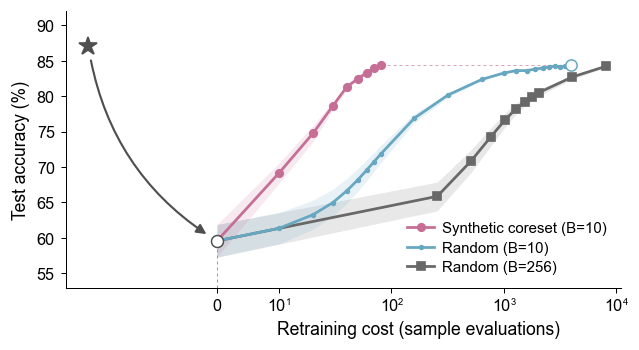

In [ ]:
from matplotlib.patches import ConnectionPatch
from matplotlib import font_manager
from matplotlib.transforms import ScaledTranslation

FONT = 'Arial' if any(f.name == 'Arial' for f in font_manager.fontManager.ttflist) else 'DejaVu Sans'
plt.rcParams.update({'font.family': FONT, 'mathtext.fontset': 'custom',
                     'mathtext.rm': FONT, 'mathtext.it': f'{FONT}:italic',
                     'mathtext.bf': f'{FONT}:bold', 'mathtext.sf': FONT, 'mathtext.cal': FONT,
                     'pdf.fonttype': 42, 'svg.fonttype': 'none'})

# Left: deployment stage, without a numerical input-budget coordinate.
# Right: measured calibration inputs; both methods start at the same zero point.
MAIN_STYLE = dict(width_mm=135, height_mm=78,
                  stage_width=1.5, curve_width=4.0,
                  axis_fontsize=10.5, tick_fontsize=9.75, legend_fontsize=9, source_x=.15,
                  mismatch_color='#4F4F4F', linewidth=1.9, show_match_guide=True)
fig = plt.figure(figsize=(MAIN_STYLE['width_mm'] / 25.4, MAIN_STYLE['height_mm'] / 25.4))
grid = fig.add_gridspec(1, 2, width_ratios=[MAIN_STYLE['stage_width'], MAIN_STYLE['curve_width']],
                       left=.105, right=.975, bottom=.19, top=.94, wspace=0)
stage = fig.add_subplot(grid[0, 0])
ax = fig.add_subplot(grid[0, 1], sharey=stage)
fig.patch.set_alpha(0)
for axis in (stage, ax):
    axis.patch.set_alpha(0)
stage.set(xlim=(0, 1), ylim=(53, 92), ylabel='Test accuracy (%)')
stage.yaxis.label.set_fontsize(MAIN_STYLE['axis_fontsize'])
stage.tick_params(axis='both', labelsize=MAIN_STYLE['tick_fontsize'], width=.6, length=3)
ax.tick_params(axis='both', labelsize=MAIN_STYLE['tick_fontsize'], width=.6, length=3)
for axis in (stage, ax):
    for spine in axis.spines.values():
        spine.set_linewidth(.6)
stage.set_xticks([])
stage.set_yticks([55, 60, 65, 70, 75, 80, 85, 90])
stage.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', left=False, labelleft=False)
ax.set_xscale('symlog', linthresh=10, linscale=.5)
ax.set_xlim(0, 11000)
ax.set_xticks([0, 10, 100, 1000, 10000])
# Draw all exponents consistently in small Arial digits; some Arial versions
# lack Unicode superscript 4, and mathtext's default exponent is too large here.
ax.set_xticklabels(['0', '10', '10', '10', '10'])
exponent_pt = 5.7
renderer = fig.canvas.get_renderer()
base_fp = font_manager.FontProperties(family=FONT, size=MAIN_STYLE['tick_fontsize'])
exponent_fp = font_manager.FontProperties(family=FONT, size=exponent_pt)
base_width = renderer.get_text_width_height_descent('10', base_fp, False)[0] * 72 / fig.dpi
for tick, position, exponent in zip(ax.xaxis.get_major_ticks()[1:], [10, 100, 1000, 10000], '1234'):
    exponent_width = renderer.get_text_width_height_descent(exponent, exponent_fp, False)[0] * 72 / fig.dpi
    shift_pt = (base_width - exponent_width) / 2
    transform = tick.label1.get_transform() + ScaledTranslation(shift_pt / 72, 0, fig.dpi_scale_trans)
    tick.label1.set_ha('right')
    tick.label1.set_transform(transform)
    ax.annotate(exponent, xy=(position, 0), xycoords=transform, xytext=(.1, .5),
                textcoords='offset points', ha='left', va='top', fontsize=exponent_pt,
                fontfamily=FONT, annotation_clip=False)
ax.set_xlabel('Retraining cost (sample evaluations)', fontsize=MAIN_STYLE['axis_fontsize'])

initial = np.asarray(main['static']['direct_load']['per_chip'])
ideal = main['static']['ideal']['mean']
dd = main['static']['dd80']
random_curves = dict(main['static']['fresh10_long']['curves'])
random_curves.update({k: row['per_chip'] for k, row in extension['curves'].items()})
full = main['static']['full256_long']

# Display only recorded points up to the relevant endpoint, without changing
# the stored results or forcing either baseline to equal the coreset accuracy.
match_step = extension['threshold']['first_recorded_step']
random_stop = match_step if match_step is not None else max(map(int, random_curves))
full_stop = min(map(int, full['curves']),
                key=lambda k: abs(np.mean(full['curves'][str(k)]) - dd['mean']))
random_display = {k: v for k, v in random_curves.items() if int(k) <= random_stop}
full_display = {k: v for k, v in full['curves'].items() if int(k) <= full_stop}
# Shared helper uses 4,000 chip-level bootstrap resamples and percentile CIs.
draw_curve(ax, full_display, full['B'], f"Random (B={full['B']})", STYLE['full'], marker='s', zorder=2)
draw_curve(ax, random_display, 10, 'Random (B=10)', STYLE['random'], marker='.', zorder=3)
draw_curve(ax, dd['curves'], dd['B'], f"Synthetic coreset (B={dd['B']})", STYLE['coreset'], marker='o', zorder=5)
for line in ax.lines:
    line.set_linewidth(1.65)
    line.set_markersize(4.5)
stage.plot(MAIN_STYLE['source_x'], ideal, marker='*', ms=11.25, color=MAIN_STYLE['mismatch_color'], zorder=6)

arrow = ConnectionPatch(xyA=(MAIN_STYLE['source_x'], ideal), coordsA=stage.transData,
                        xyB=(0, initial.mean()), coordsB=ax.transData,
                        arrowstyle='-|>', connectionstyle='arc3,rad=.23',
                        shrinkA=9, shrinkB=7.5, mutation_scale=12, linewidth=1.275,
                        color=MAIN_STYLE['mismatch_color'], clip_on=False)
fig.add_artist(arrow)

ax.plot(0, initial.mean(), 'o', ms=7.2, mfc='white', mec=MAIN_STYLE['mismatch_color'],
        mew=.9, zorder=10, clip_on=False)
ax.vlines(0, 53, initial.mean()-1.2, color='#999999', lw=.6, linestyles=(0, (3, 3)), clip_on=False)
if MAIN_STYLE['show_match_guide'] and match_step is not None:
    matched = extension['curves'][str(match_step)]
    budget = matched['presentations']
    ax.plot(budget, matched['mean'], 'o', ms=6.75, mfc='white', mec=STYLE['random'], mew=.9, zorder=6)
    ax.hlines(dd['mean'], dd['presentations'], budget, color=STYLE['coreset'],
              linewidth=.6, linestyles=(0, (3, 3)), alpha=.65)

# Keep only the curve legend and axis labels; explanatory text is added later.
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='lower right',
          fontsize=MAIN_STYLE['legend_fontsize'], frameon=False,
          handlelength=1.8, handletextpad=.55, labelspacing=.35)

if SAVE_FIGURES:
    # Preserve the entire 135 mm canvas; tight cropping would change its width.
    with plt.rc_context({'savefig.bbox': None}):
        for suffix in ['png', 'pdf', 'svg']:
            fig.savefig(flat_result_path(FIGURES / f'mzi_main_results.{suffix}'), bbox_inches=None,
                        dpi=300, transparent=True, facecolor='none', edgecolor='none')
plt.show()


## 5. Supplementary results — Supplementary Figure 7

Run the blocks in order to compute ablations and hardware mismatch from Fashion-MNIST.
Hyperparameters and checkpoints are selected on validation data.


In [8]:
from utils.datasets import load_fmnist, save_checkpoint, save_json
from utils.preprocessing import split_fmnist_for_mzi
from utils.mzi_training import (
    load_source,
    balanced_indices,
    cyclic_batches,
    random_batches,
    accuracy,
)
from utils.mzi_network import make_chips
from utils.pat import adapt, expand_state, per_chip_ce, pat_grad


import math
from utils.plotting import muted_magma


SI_ROOT = ROOT
SI_DIR = ROOT / "results/simulation/mzi/ablations"
SI_SOURCE = RERUN / "source.pt"
SI_CONFIG = copy.deepcopy(config)
SI_DEVICE = DEVICE
SUPP_FIGURES = FIGURES / "supplementary"
flat_result_directory(SI_DIR).mkdir(parents=True, exist_ok=True)
SI_OUTER = 2000
SI_FIXED_LR = 0.0003
SI_FIXED_MOMENTUM = 0.9
SI_BASELINE_RATES = [0.0003, 0.001, 0.002, 0.003]
SI_BASELINE_MAX = 4096
SI_BASELINE_PATIENCE = 6
SI_BASELINE_MIN_GAIN_PP = 0.02

publication_style()
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "svg.fonttype": "none",
        "mathtext.fontset": "dejavusans",
    }
)


def show_supplement(fig, name):
    if SAVE_FIGURES:
        export_figure(fig, SUPP_FIGURES, name)
        fig.savefig(flat_result_path(SUPP_FIGURES / f"{name}.svg"), bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def si_stats(values):
    v = np.asarray(values, dtype=float)
    ix = np.random.default_rng(20261009).integers(0, len(v), (4000, len(v)))
    return dict(
        mean=float(v.mean()),
        sd=float(v.std(ddof=1)),
        ci95=np.quantile(v[ix].mean(1), [0.025, 0.975]).tolist(),
        per_chip=v.tolist(),
    )


def si_context():
    dataset = split_fmnist_for_mzi(
        load_fmnist(SI_ROOT / "dataset", device=SI_DEVICE, download=False),
        seed=SI_CONFIG["split_seed"],
    )
    source, encoder, net = load_source(SI_SOURCE, SI_DEVICE)
    return dict(
        dataset=dataset,
        source=source,
        encoder=encoder,
        net=net,
        fields=[encoder.encode(x) for x, y in dataset],
    )


### 5.1 Distillation convergence — Supplementary Figure 7a

Validation accuracy after eight adaptation steps, evaluated every 100 outer
distillation steps on 32 validation devices. 

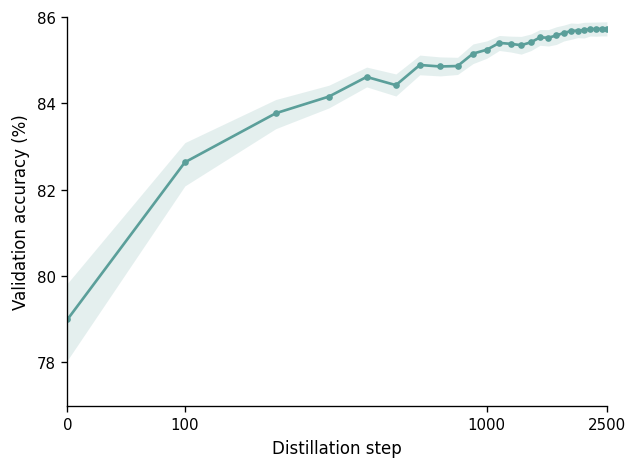

In [9]:
history = json.loads((flat_result_path(RERUN / "coreset.history.json")).read_text())
steps = np.array([row["it"] for row in history["rows"]])
device_accuracy = 100 * np.array([row["per_chip"] for row in history["rows"]])
means = device_accuracy.mean(axis=1)
indices = np.random.default_rng(20261009).integers(
    0, device_accuracy.shape[1], size=(4000, device_accuracy.shape[1])
)
low, high = np.quantile(device_accuracy[:, indices].mean(-1), [0.025, 0.975], axis=1)

fig, ax = plt.subplots(figsize=(5.2, 3.8), layout="constrained")
ax.fill_between(steps, low, high, color="#5B9F9A", alpha=0.16, lw=0)
ax.plot(steps, means, color="#5B9F9A", marker="o", ms=3, lw=1.6)
ax.set_xscale("symlog", linthresh=100, linscale=0.35)
ax.set(xlabel="Distillation step", ylabel="Validation accuracy (%)", xlim=(0, 2500), ylim=(77, 86))
ax.set_xticks([0, 100, 1000, 2500], ["0", "100", "1000", "2500"])
ax.set_yticks([78, 80, 82, 84, 86])
show_supplement(fig, "distillation_convergence")


### 5.2 Fixed and learnable update parameters — Supplementary Figure 7b



In [10]:
def si_rule(ck):
    if ck["rule_kind"] == "learned":
        return dict(
            lr=ck["lr"], opt="sgd", precond=ck["pre"], momentum_schedule=ck["momentum_schedule"]
        )
    return dict(lr=SI_FIXED_LR, opt="sgd", betas=(SI_FIXED_MOMENTUM, 0.999))


def si_evaluate(ctx, ck=None, *, split="test", K=None, B=10, lr=None, opt="sgd", random_seed=7699):
    config = SI_CONFIG
    seeds = config["test_chips" if split == "test" else "validation_chips"]
    j = 2 if split == "test" else 1
    z = ctx["fields"][j]
    y = ctx["dataset"][j][1]
    net = ctx["net"]
    K = ck["K"] if ck is not None else K
    checks = (
        set(range(K + 1)) if K <= 12 else {0, 8, 16, 32, 64, 128, K} | set(range(256, K + 1, 128))
    )
    curves = {str(k): [] for k in sorted(checks)}
    for start in range(0, len(seeds), config["chip_batch"]):
        group = seeds[start : start + config["chip_batch"]]
        C = len(group)
        chips = make_chips(group, net, SI_DEVICE, config["errors"])
        state = expand_state(ctx["source"]["st"], C)
        if ck is not None:
            data = cyclic_batches(ctx["encoder"].field(ck["u"]), ck["t"], ck["B"], C)
            kw = si_rule(ck)
        else:
            data = random_batches(ctx["fields"][0], ctx["dataset"][0][1], B, random_seed, C)
            kw = dict(lr=lr, opt=opt, betas=(SI_FIXED_MOMENTUM, 0.999))

        def record(k, out):
            if k in checks:
                curves[str(k)].extend((100 * accuracy(net, out, z, y, chips)).tolist())

        record(0, state)
        out = adapt(net, state, data, chips, K, callback=record, **kw)
        assert torch.isfinite(out["th"]).all() and torch.isfinite(out["ph"]).all()
    return dict(
        **si_stats(curves[str(K)]), curves=curves, K=K, B=B if ck is None else ck["B"], split=split
    )


In [11]:
def si_distill(ctx, K, learned=True):
    kind = "learned" if learned else "fixed"
    label = f"{kind}_K{K}"
    folder = SI_DIR / "trials" / label
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)
    final_path = folder / "coreset_last.pt"
    resume_path = folder / "coreset_resume.pt"
    cfg = copy.deepcopy(SI_CONFIG["distillation"])
    cfg.update(M=10 * K, B=10, K=K, outer=2500)
    save_json(
        folder / "config.json",
        dict(
            distillation=cfg,
            stop_after=SI_OUTER,
            rule_kind=kind,
            fixed_lr=SI_FIXED_LR,
            fixed_momentum=SI_FIXED_MOMENTUM,
        ),
    )
    if flat_result_path(final_path).exists():
        ck = torch.load(flat_result_path(final_path), map_location=SI_DEVICE, weights_only=True)
        assert ck['completed_outer'] == SI_OUTER
        return ck
    torch.manual_seed(cfg["seed"])
    enc = ctx["encoder"]
    net = ctx["net"]
    (x, y) = ctx["dataset"][0]
    ids = balanced_indices(y, K, cfg["seed"]).view(10, -1).T.flatten()
    u = enc.u(x)[ids].detach().clone().requires_grad_()
    t = F.one_hot(y[ids], 10).float().requires_grad_()
    raw = dict(inputs=u, targets=t)
    groups = [dict(params=[u, t], lr=cfg["data_lr"])]
    if learned:
        raw.update(
            log_lr=torch.full(
                (K, net.L, 1), math.log(cfg["inner_lr"]), device=SI_DEVICE, requires_grad=True
            ),
            log_theta=torch.zeros(K, net.L, net.geo.n, device=SI_DEVICE, requires_grad=True),
            log_phi=torch.zeros(K, net.L, net.geo.n, device=SI_DEVICE, requires_grad=True),
            raw_momentum=torch.full(
                (K,), math.log(0.5 / (0.99 - 0.5)), device=SI_DEVICE, requires_grad=True
            ),
        )
        groups += [
            dict(params=[raw["log_lr"], raw["log_theta"], raw["log_phi"]], lr=cfg["rule_lr"]),
            dict(params=[raw["raw_momentum"]], lr=cfg["momentum_lr"]),
        ]
    optimizer = torch.optim.Adam(groups)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, cfg["outer"])
    chip_rng = torch.Generator().manual_seed(cfg["seed"] + 100)
    query_rng = torch.Generator(device=SI_DEVICE).manual_seed(cfg["seed"] + 200)
    rows = []
    best = -1.0
    start = 0
    candidate = resume_path if flat_result_path(resume_path).exists() else None
    if candidate:
        ck = torch.load(flat_result_path(candidate), map_location=SI_DEVICE, weights_only=True)
        assert ck['K'] == K and ck['M'] == 10 * K
        assert ck["config"]["outer"] == 2500
        for (name, param) in raw.items():
            with torch.no_grad():
                param.copy_(ck["raw_parameters"][name])
        optimizer.load_state_dict(ck["optimizer_state"])
        scheduler.load_state_dict(ck["scheduler_state"])
        chip_rng.set_state(ck["chip_rng_state"].cpu())
        query_rng.set_state(ck["query_rng_state"].cpu())
        start = ck["completed_outer"]
        rows = ck["rows"]
        best = ck["best_dev"]
        save_json(
            folder / "continuation.json",
            dict(
                from_path=str(flat_result_path(candidate).relative_to(SI_ROOT)), outer=start, optimizer_restored=True
            ),
        )

    def checkpoint(it):
        result = dict(
            u=u,
            t=t,
            ids=ids,
            M=10 * K,
            B=10,
            K=K,
            opt="sgd",
            rule_kind=kind,
            completed_outer=it,
            config=cfg,
            rows=list(rows),
            best_dev=best,
            raw_parameters=raw,
            optimizer_state=optimizer.state_dict(),
            scheduler_state=scheduler.state_dict(),
            chip_rng_state=chip_rng.get_state(),
            query_rng_state=query_rng.get_state(),
        )
        if learned:
            result.update(
                lr=raw["log_lr"].exp(),
                pre=dict(th=raw["log_theta"].exp(), ph=raw["log_phi"].exp(), _perstep=True),
                momentum_schedule=0.99 * raw["raw_momentum"].sigmoid(),
            )
        else:
            result.update(
                lr=SI_FIXED_LR, fixed_pat=dict(lr=SI_FIXED_LR, momentum=SI_FIXED_MOMENTUM)
            )
        return result

    for it in range(start, SI_OUTER + 1):
        if it % 100 == 0 and (not any((r["it"] == it for r in rows))):
            ck = checkpoint(it)
            for key in ["u", "t", "lr", "momentum_schedule"]:
                if torch.is_tensor(ck.get(key)):
                    ck[key] = ck[key].detach()
            if learned:
                ck["pre"] = {
                    k: v.detach() if torch.is_tensor(v) else v for (k, v) in ck["pre"].items()
                }
            val = si_evaluate(ctx, ck, split="validation")
            score = val["mean"] / 100
            assert math.isfinite(score)
            rows.append(
                dict(it=it, dev=score, per_chip=(np.asarray(val["per_chip"]) / 100).tolist())
            )
            if score > best:
                best = score
                save_checkpoint(folder / "coreset_best.pt", checkpoint(it))
            save_json(folder / "coreset.history.json", dict(rows=rows, best_dev=best))
            save_checkpoint(resume_path, checkpoint(it))
        if it == SI_OUTER:
            break
        C = cfg["chips_per_step"]
        (lo, hi) = SI_CONFIG["training_chip_pool"]
        seeds = (lo + torch.randint(hi - lo + 1, (C,), generator=chip_rng)).tolist()
        chips = make_chips(seeds, net, SI_DEVICE, SI_CONFIG["errors"])
        state = adapt(
            net,
            expand_state(ctx["source"]["st"], C),
            cyclic_batches(enc.field(u), t, 10, C),
            chips,
            K,
            create_graph=True,
            **si_rule(checkpoint(it)),
        )
        query = torch.randint(
            len(x), (C, cfg["query_batch"]), device=SI_DEVICE, generator=query_rng
        )
        loss = per_chip_ce(net.forward(state, ctx["fields"][0][query], chips), y[query]) / C
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite meta objective")
        optimizer.zero_grad()
        loss.backward()
        assert all((p.grad is not None and torch.isfinite(p.grad).all() for p in raw.values()))
        torch.nn.utils.clip_grad_norm_(list(raw.values()), 1.0)
        optimizer.step()
        scheduler.step()
        del state, loss, query, chips
    save_checkpoint(final_path, checkpoint(SI_OUTER))
    return torch.load(flat_result_path(final_path), map_location=SI_DEVICE, weights_only=True)


In [12]:
result_path = SI_DIR / "results.json"
results = json.loads(flat_result_path(result_path).read_text()) if flat_result_path(result_path).exists() else {}
ctx = si_context()
for learned in [False, True]:
    label = "learned_K8" if learned else "fixed_K8"
    if label not in results:
        checkpoint = si_distill(ctx, K=8, learned=learned)
        result = si_evaluate(ctx, checkpoint)
        result.update(outer=SI_OUTER, M=80, rule_kind="learned" if learned else "fixed")
        results[label] = result
        save_json(result_path, results)


The Random baseline uses eight updates with batch size ten. Its SGD/Adam rule
is selected on 32 validation devices from the grid below, including the local
refinement. Three sampling streams are averaged per device; the winning rule
is then evaluated on 64 test devices. 


In [13]:
RANDOM_TUNING_GRID = [
    dict(opt="sgd", lr=lr, momentum=mu)
    for lr in [0.00015, 0.0003, 0.0006, 0.001]
    for mu in [0.5, 0.9]
] + [dict(opt="adam", lr=lr, momentum=0.9) for lr in [0.001, 0.003]]
RANDOM_REFINEMENT_GRID = [
    dict(opt="sgd", lr=lr, momentum=mu) for lr in [0.0008, 0.001, 0.0012] for mu in [0.4, 0.5, 0.6]
]
RANDOM_TUNING_GRID += [
    recipe for recipe in RANDOM_REFINEMENT_GRID if recipe not in RANDOM_TUNING_GRID
]


def si_random_recipe_eval(ctx, recipe, split, sampling_seed):
    j = 1 if split == "validation" else 2
    seeds = SI_CONFIG["validation_chips" if j == 1 else "test_chips"]
    curves = {str(k): [] for k in ([0, 8] if j == 1 else range(9))}
    net = ctx["net"]
    for start in range(0, len(seeds), SI_CONFIG["chip_batch"]):
        group = seeds[start : start + SI_CONFIG["chip_batch"]]
        C = len(group)
        hardware = make_chips(group, net, SI_DEVICE, SI_CONFIG["errors"])
        state = expand_state(ctx["source"]["st"], C)

        def record(k, out):
            if str(k) in curves:
                curves[str(k)].extend(
                    (
                        100 * accuracy(net, out, ctx["fields"][j], ctx["dataset"][j][1], hardware)
                    ).tolist()
                )

        record(0, state)
        out = adapt(
            net,
            state,
            random_batches(ctx["fields"][0], ctx["dataset"][0][1], 10, sampling_seed, C),
            hardware,
            8,
            recipe["lr"],
            opt=recipe["opt"],
            betas=(recipe["momentum"], 0.999),
            callback=record,
        )
    return dict(**si_stats(curves["8"]), curves=curves, split=split, B=10, K=8, recipe=recipe)


tuning_dir = SI_DIR / "random_small_tuning"
flat_result_directory(tuning_dir).mkdir(exist_ok=True)
ctx = si_context()
trials = []
for (i, recipe) in enumerate(RANDOM_TUNING_GRID):
    path = tuning_dir / f"validation_trial{i}.json"
    if flat_result_path(path).exists():
        trial = json.loads(flat_result_path(path).read_text())
    else:
        runs = [
            si_random_recipe_eval(ctx, recipe, "validation", seed)
            for seed in [7697, 7698, 7699]
        ]
        values = np.mean([run["per_chip"] for run in runs], axis=0)
        trial = dict(recipe=recipe, validation=si_stats(values), raw_runs=runs)
        save_json(path, trial)
    assert trial["recipe"] == recipe
    trials.append(trial)
winner = max(trials, key=lambda trial: trial["validation"]["mean"])
selection = dict(
    recipe=winner["recipe"],
    validation_accuracy=winner["validation"]["mean"],
    criterion="Mean of 32 validation devices after averaging 3 sampling streams per device",
    grid=RANDOM_TUNING_GRID,
    test_used_for_selection=False,
)
save_json(tuning_dir / "selection.json", selection)
recipe_key = (
    winner["recipe"]["opt"]
    + "_lr"
    + str(winner["recipe"]["lr"])
    + "_mu"
    + str(winner["recipe"]["momentum"])
)
test_path = tuning_dir / ("selected_test_" + recipe_key + ".json")
previous_path = tuning_dir / "selected_test.json"
if flat_result_path(previous_path).exists():
    previous = json.loads(flat_result_path(previous_path).read_text())
    if previous["recipe"] == winner["recipe"] and (not flat_result_path(test_path).exists()):
        save_json(test_path, previous)
if flat_result_path(test_path).exists():
    selected = json.loads(flat_result_path(test_path).read_text())
    assert selected["recipe"] == winner["recipe"]
    selected["selection"] = selection
else:
    runs = [
        si_random_recipe_eval(ctx, winner["recipe"], "test", seed)
        for seed in [7600, 7601, 7602]
    ]
    curves = {
        str(k): np.mean([run["curves"][str(k)] for run in runs], axis=0).tolist()
        for k in range(9)
    }
    selected = dict(
        **si_stats(curves["8"]),
        curves=curves,
        raw_runs=runs,
        selection=selection,
        B=10,
        K=8,
        split="test",
        recipe=winner["recipe"],
    )
    save_json(test_path, selected)
save_json(tuning_dir / "selected_test.json", selected)
results = json.loads((flat_result_path(SI_DIR / "results.json")).read_text())
results["random_K8"] = selected
save_json(SI_DIR / "results.json", results)


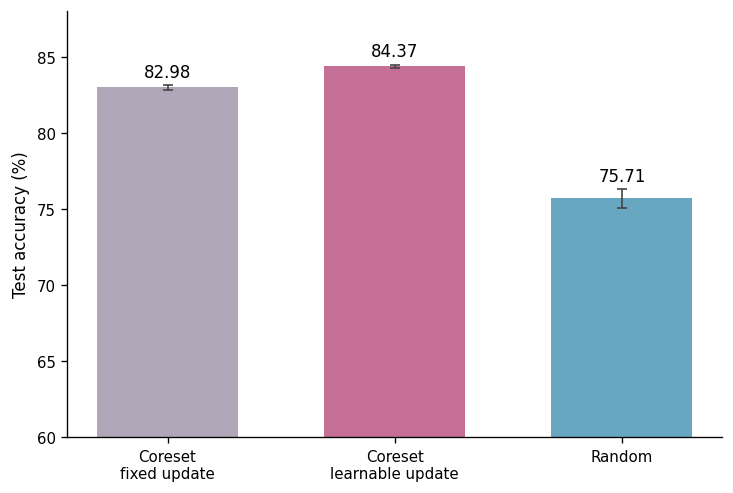

In [14]:
keys = ["fixed_K8", "learned_K8", "random_K8"]
means = np.array([results[key]["mean"] for key in keys])
intervals = np.array([results[key]["ci95"] for key in keys])
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.bar(
    np.arange(len(keys)),
    means,
    color=["#B1A6B7", "#C66F96", "#67A7C1"],
    width=0.62,
    yerr=np.stack([means - intervals[:, 0], intervals[:, 1] - means]),
    error_kw=dict(ecolor="#444444", capsize=3, elinewidth=1),
)
for i, (value, upper) in enumerate(zip(means, intervals[:, 1])):
    ax.annotate(f"{value:.2f}", (i, upper), xytext=(0, 5), textcoords="offset points", ha="center")
ax.set_xticks(
    np.arange(len(keys)), ["Coreset\nfixed update", "Coreset\nlearnable update", "Random"]
)
ax.set(ylabel="Test accuracy (%)", ylim=(60, 88))

show_supplement(fig, "update_rule")


### 5.3 Synthetic sample count and adaptation steps — Supplementary Figure 7c

Learnable-rule coresets use 20/50/80/120 samples for 2/5/8/12 updates, with
batch size ten and 2,000 outer steps in every condition. The Random reference
uses batch size 256; its Adam rate and stopping point are selected on validation
devices. Test results average three random sampling streams per device.


In [15]:
def si_adam_step(net, state, fields, targets, chips, m, v, step, lr):
    (gradients, _) = pat_grad(net, state, fields, targets, chips)
    out = dict(state)
    for key in ["th", "ph"]:
        m[key] = (0.9 * m[key] + 0.1 * gradients[key]).detach()
        v[key] = (0.999 * v[key] + 0.001 * gradients[key].square()).detach()
        mh = m[key] / (1 - 0.9**step)
        vh = v[key] / (1 - 0.999**step)
        update = mh / ((vh + 1e-16).sqrt() + 1e-08)
        out[key] = (state[key] - lr * update).detach().requires_grad_()
    return out


def si_long_baseline(ctx):
    folder = SI_DIR / "baseline_B256"
    flat_result_directory(folder).mkdir(exist_ok=True)
    chosen_path = folder / "selection.json"
    if flat_result_path(chosen_path).exists():
        return json.loads(flat_result_path(chosen_path).read_text())
    trials = []
    net = ctx["net"]
    seeds = SI_CONFIG["validation_chips"]
    C = len(seeds)
    for lr in SI_BASELINE_RATES:
        output = folder / f"validation_lr{lr:g}.json"
        if flat_result_path(output).exists():
            trials.append(json.loads(flat_result_path(output).read_text()))
            continue
        chips = make_chips(seeds, net, SI_DEVICE, SI_CONFIG["errors"])
        st = expand_state(ctx["source"]["st"], C)
        m = {k: torch.zeros_like(st[k]) for k in ["th", "ph"]}
        v = {k: torch.zeros_like(st[k]) for k in m}
        data = random_batches(ctx["fields"][0], ctx["dataset"][0][1], 256, 7699, C)
        rows = []
        best = -1.0
        best_step = None
        anchor = -1.0
        stale = 0
        reason = "maximum_steps"
        for step in range(1, SI_BASELINE_MAX + 1):
            (x, y) = data(step - 1)
            st = si_adam_step(net, st, x, y, chips, m, v, step, lr)
            assert torch.isfinite(st["th"]).all() and torch.isfinite(st["ph"]).all()
            if step in [8, 16, 32, 64] or step % 128 == 0:
                values = (
                    100 * accuracy(net, st, ctx["fields"][1], ctx["dataset"][1][1], chips)
                ).tolist()
                score = float(np.mean(values))
                rows.append(dict(step=step, mean=score, per_chip=values))
                if score > best:
                    best = score
                    best_step = step
                if step % 128 == 0:
                    if score > anchor + SI_BASELINE_MIN_GAIN_PP:
                        anchor = score
                        stale = 0
                    else:
                        stale += 1
                save_json(folder / f"partial_lr{lr:g}.json", dict(rows=rows))
                if step >= 512 and stale >= SI_BASELINE_PATIENCE:
                    reason = "validation_plateau"
                    break
        trial = dict(
            lr=lr, K=best_step, best_validation=best, stopped_at=step, reason=reason, rows=rows
        )
        save_json(output, trial)
        trials.append(trial)
    chosen = max(trials, key=lambda row: row["best_validation"])
    selected = dict(
        B=256,
        opt="adam",
        lr=chosen["lr"],
        K=chosen["K"],
        validation_accuracy=chosen["best_validation"],
        selected_on="32 validation devices; 5000 validation images; single validation sampling stream7699",
        maximum_steps=SI_BASELINE_MAX,
        trials=[{k: v for (k, v) in t.items() if k != "rows"} for t in trials],
        interpretation="Empirical long-run reference, not a mathematical upper bound",
    )
    save_json(chosen_path, selected)
    return selected


In [16]:
for K in [2, 5, 12]:
    label = f"learned_K{K}"
    if label not in results:
        checkpoint = si_distill(ctx, K, learned=True)
        result = si_evaluate(ctx, checkpoint)
        result.update(outer=SI_OUTER, M=10 * K, rule_kind="learned")
        results[label] = result
        save_json(result_path, results)
selected = si_long_baseline(ctx)
if "random_B256_long" not in results:
    runs = []
    for seed in [7700, 7701, 7702]:
        run_path = SI_DIR / "baseline_B256" / f"test_seed{seed}.json"
        if flat_result_path(run_path).exists():
            run = json.loads(flat_result_path(run_path).read_text())
        else:
            run = si_evaluate(
                ctx, K=selected["K"], B=256, lr=selected["lr"], opt="adam", random_seed=seed
            )
            save_json(run_path, run)
        runs.append(run)
    values = np.mean([r["per_chip"] for r in runs], axis=0)
    results["random_B256_long"] = dict(
        **si_stats(values),
        raw_runs=runs,
        selection=selected,
        split="test",
        B=256,
        K=selected["K"],
    )
    save_json(result_path, results)


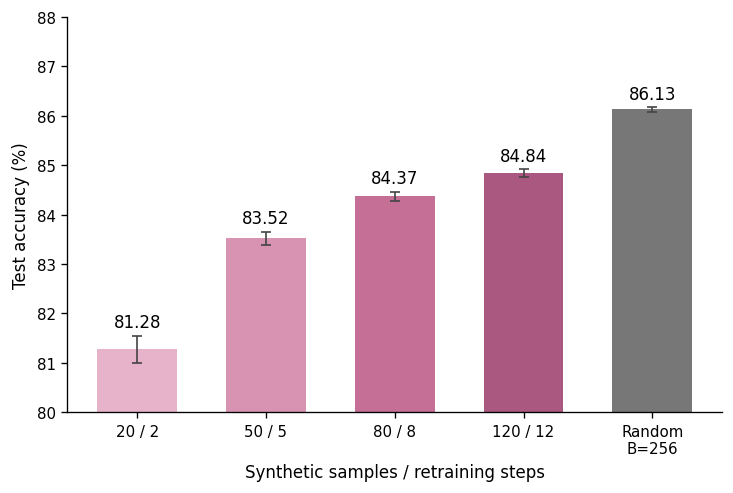

In [17]:
keys = ["learned_K2", "learned_K5", "learned_K8", "learned_K12", "random_B256_long"]
means = np.array([results[key]["mean"] for key in keys])
intervals = np.array([results[key]["ci95"] for key in keys])
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.bar(
    np.arange(len(keys)),
    means,
    color=["#E6B3CA", "#D892B2", "#C66F96", "#AA587F", "#777777"],
    width=0.62,
    yerr=np.stack([means - intervals[:, 0], intervals[:, 1] - means]),
    error_kw=dict(ecolor="#444444", capsize=3, elinewidth=1),
)
for i, (value, upper) in enumerate(zip(means, intervals[:, 1])):
    ax.annotate(f"{value:.2f}", (i, upper), xytext=(0, 5), textcoords="offset points", ha="center")
ax.set_xticks(np.arange(len(keys)), ["20 / 2", "50 / 5", "80 / 8", "120 / 12", "Random\nB=256"])
ax.set(ylabel="Test accuracy (%)", ylim=(80, 88))
ax.set_xlabel("Synthetic samples / retraining steps")
show_supplement(fig, "sample_count")


### 5.4 Original and distilled inputs — Supplementary Figure 7d

The ten examples below were chosen across batches for visual illustration;
they are not one adaptation batch or a representative statistical sample.
Class names identify the initialization images. PCA back-projections are
displayed in [0, 1]; adaptation uses the signed PCA coefficients and raw signed
targets. The arrays are reconstructed directly from Fashion-MNIST and the
selected main checkpoint using the indices below.


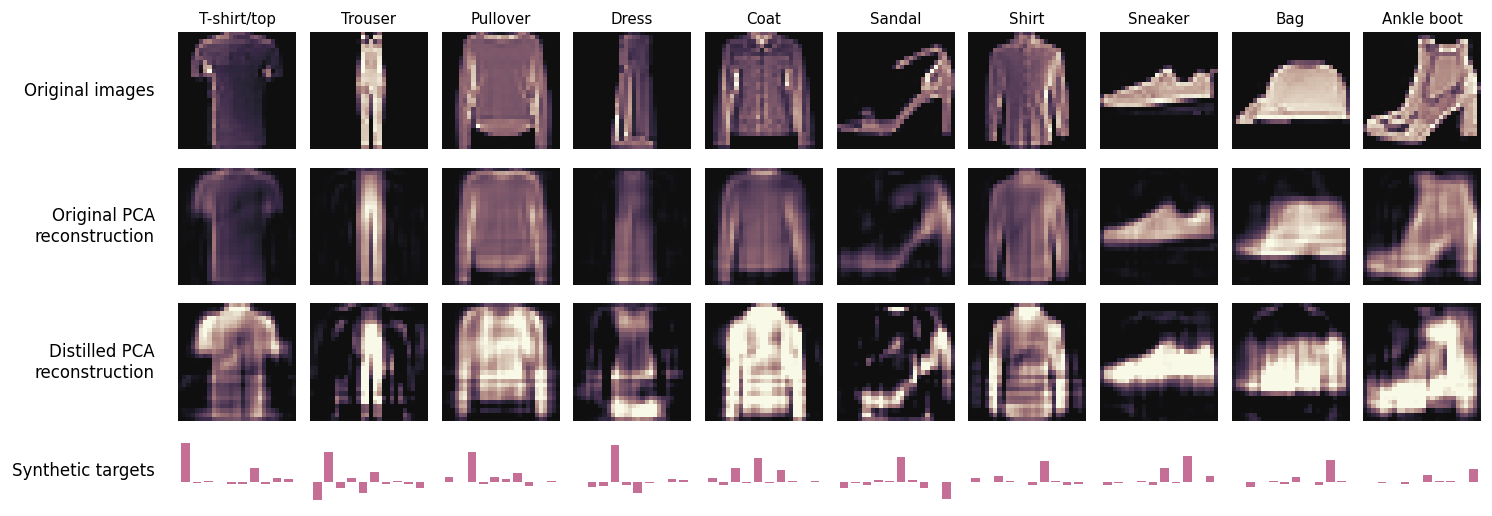

In [18]:
example_ids = torch.tensor([40, 1, 62, 3, 64, 55, 46, 77, 38, 59])
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]
gallery_source, gallery_encoder, _ = load_source(SI_SOURCE, "cpu")
gallery_checkpoint = torch.load(flat_result_path(RERUN / "coreset.pt"), map_location="cpu", weights_only=True)
gallery_dataset = split_fmnist_for_mzi(
    load_fmnist(ROOT / "dataset", device="cpu", download=False), seed=SI_CONFIG["split_seed"]
)
seed_indices = gallery_checkpoint["ids"][example_ids]
seed_images = gallery_dataset[0][0][seed_indices]
with torch.no_grad():
    seed_u = gallery_encoder.u(seed_images)
    synthetic_u = gallery_checkpoint["u"][example_ids]
    pca_pixels = (seed_u / gallery_encoder.s) @ gallery_encoder.P + gallery_encoder.mean
    synthetic_pixels = (synthetic_u / gallery_encoder.s) @ gallery_encoder.P + gallery_encoder.mean
original_pixels = seed_images.numpy().reshape(10, 28, 28)
pca_pixels = pca_pixels.numpy().reshape(10, 28, 28)
synthetic_pixels = synthetic_pixels.numpy().reshape(10, 28, 28)
targets = gallery_checkpoint["t"][example_ids].numpy()
del gallery_dataset

fig = plt.figure(figsize=(13, 4.6))
grid = fig.add_gridspec(
    4,
    10,
    left=0.16,
    right=0.995,
    bottom=0.05,
    top=0.91,
    height_ratios=[1, 1, 1, 0.55],
    hspace=0.12,
    wspace=0.12,
)
row_labels = [
    "Original images",
    "Original PCA\nreconstruction",
    "Distilled PCA\nreconstruction",
    "Synthetic targets",
]
gallery_axes = []
for row in range(4):
    axes = []
    for col in range(10):
        ax = fig.add_subplot(grid[row, col])
        if row < 3:
            ax.imshow(
                [original_pixels, pca_pixels, synthetic_pixels][row][col],
                cmap=muted_magma(),
                vmin=0,
                vmax=1,
                interpolation="nearest",
            )
        else:
            ax.bar(np.arange(10), targets[col], color="#C66F96", width=0.76)
            ax.set(xlim=(-0.65, 9.65), ylim=(-1.05, 2.2))
        ax.set_axis_off()
        if row == 0:
            ax.set_title(class_names[col], fontsize=9, pad=5)
        axes.append(ax)
    box = axes[0].get_position()
    fig.text(0.145, (box.y0 + box.y1) / 2, row_labels[row], ha="right", va="center", fontsize=10)
    gallery_axes.append(axes)
show_supplement(fig, "coreset_examples")


## 6. Changes in fabrication-error distributions — Supplementary Figure 9

Use the same source network, 80 synthetic inputs, learned update rule and 64 test devices.
Each adaptation uses eight batches of ten inputs; the electronic readout stays fixed.
Random uses the nominal-validation-selected Adam recipe and three sampling streams,
averaged within each device. Error bars show 95% bootstrap confidence intervals over devices
(4,000 resamples, seed 20261010). No settings are selected using these test results.

The following cells compute all eight conditions using the source and coreset trained above.


In [19]:
def mismatch_chips(family, value, seeds, net, errors, device):
    chips = []
    for seed in seeds:
        rng = torch.Generator().manual_seed(int(seed))
        # Keep the original six float64 draws and cast only after building the chip.
        z = [torch.randn(net.L, net.geo.n, generator=rng, dtype=torch.float64) for _ in range(6)]
        phase_mean = value if family == "phase_bias" else 0.0
        phase_sd = value if family == "phase_sd" else errors["sph"]
        phase = [phase_mean + phase_sd * a for a in z[:2]]
        angles = [errors["sbs"] * a for a in z[2:4]]
        if family == "splitter_rho":
            shared_rng = torch.Generator().manual_seed(int(seed) + 90000000)
            common = torch.randn((), generator=shared_rng, dtype=torch.float64)
            angles = [
                errors["sbs"] * (math.sqrt(value) * common + math.sqrt(1 - value) * a)
                for a in z[2:4]
            ]
        elif family == "splitter_offset":
            angles = [torch.full_like(a, value) for a in z[2:4]]
        a1, a2 = angles
        la, lb = [errors["loss_db"] + errors["loss_sd"] * a for a in z[4:6]]
        chips.append(
            dict(
                dth=phase[0],
                dph=phase[1],
                c1=torch.cos(math.pi / 4 + a1),
                s1=torch.sin(math.pi / 4 + a1),
                c2=torch.cos(math.pi / 4 + a2),
                s2=torch.sin(math.pi / 4 + a2),
                ea=10 ** (-la / 20),
                eb=10 ** (-lb / 20),
            )
        )
    return {k: torch.stack([c[k] for c in chips]).float().to(device) for k in chips[0]}


def mismatch_stats(values):
    values = np.asarray(values, dtype=float)
    indices = np.random.default_rng(20261010).integers(0, len(values), (4000, len(values)))
    return dict(
        mean=float(values.mean()),
        sd=float(values.std(ddof=1)),
        ci95=np.quantile(values[indices].mean(1), [0.025, 0.975]).tolist(),
        per_chip=values.tolist(),
    )


def mismatch_evaluate(ctx, ck, family, value):
    net = ctx["net"]
    seeds = SI_CONFIG["test_chips"]
    baseline = SI_CONFIG["baselines"]["fresh10"]
    recipe = baseline["recipe"]
    assert (ck["M"], ck["B"], ck["K"]) == (80, 10, 8)
    assert (baseline["B"], baseline["K"], baseline["kind"]) == (10, 8, "stream")
    fields = ctx["encoder"].field(ck["u"])
    direct, coreset = [], []
    runs = {str(seed): [] for seed in baseline["seeds"]}
    for start in range(0, len(seeds), SI_CONFIG["chip_batch"]):
        group = seeds[start : start + SI_CONFIG["chip_batch"]]
        chips = mismatch_chips(family, value, group, net, SI_CONFIG["errors"], SI_DEVICE)
        initial = expand_state(ctx["source"]["st"], len(group))

        def evaluate(state):
            return (
                100 * accuracy(net, state, ctx["fields"][2], ctx["dataset"][2][1], chips)
            ).tolist()

        direct.extend(evaluate(initial))
        data = cyclic_batches(fields, ck["t"], 10, len(group))
        out = adapt(
            net,
            initial,
            data,
            chips,
            8,
            ck["lr"],
            opt="sgd",
            precond=ck["pre"],
            momentum_schedule=ck["momentum_schedule"],
        )
        coreset.extend(evaluate(out))
        for seed in baseline["seeds"]:
            state = expand_state(ctx["source"]["st"], len(group))
            data = random_batches(ctx["fields"][0], ctx["dataset"][0][1], 10, seed, len(group))
            out = adapt(
                net,
                state,
                data,
                chips,
                8,
                recipe["lr"],
                opt=recipe["opt"],
                betas=(recipe["momentum"], 0.999),
            )
            runs[str(seed)].extend(evaluate(out))
    random = np.asarray(list(runs.values())).mean(0)
    return dict(
        direct=mismatch_stats(direct),
        coreset=mismatch_stats(coreset),
        random=dict(**mismatch_stats(random), raw_runs=runs),
    )


def mismatch_results(family, values):
    path = RERUN / "supplementary" / f"{family}.json"
    pass
    rows = [mismatch_evaluate(mismatch_ctx, mismatch_ck, family, value) for value in values]
    path = SI_ROOT / "results/simulation/mzi/supplementary" / f"{family}.json"
    flat_result_directory(path.parent).mkdir(parents=True, exist_ok=True)
    save_json(
        path,
        dict(
            family=family,
            values=values,
            rows=rows,
            coreset_outer=mismatch_ck["completed_outer"],
            test_chips=SI_CONFIG["test_chips"],
            random_recipe=SI_CONFIG["baselines"]["fresh10"],
        ),
    )
    return rows


def plot_mismatch(rows, labels, xlabel, filename):
    fig, ax = plt.subplots(figsize=(6.4, 4.3))
    positions = np.arange(len(rows))
    for index, (key, label, color) in enumerate(
        [
            ("direct", "Direct deployment", "#888888"),
            ("random", "Random", "#307eac"),
            ("coreset", "Synthetic coreset", "#b72f65"),
        ]
    ):
        mean = np.array([row[key]["mean"] for row in rows])
        ci = np.array([row[key]["ci95"] for row in rows])
        bars = ax.bar(
            positions + (index - 1) * 0.25,
            mean,
            width=0.23,
            yerr=np.vstack((mean - ci[:, 0], ci[:, 1] - mean)),
            color=color,
            label=label,
            capsize=3,
            error_kw={"linewidth": 0.8},
        )
        for bar, value, upper in zip(bars, mean, ci[:, 1]):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                max(value, upper) + 1.2,
                f"{value:.1f}",
                ha="center",
                va="bottom",
                fontsize=10,
            )
    ax.set(
        xticks=positions,
        xticklabels=labels,
        xlabel=xlabel,
        ylabel="Test accuracy (%)",
        ylim=(0, 100),
        yticks=np.arange(0, 101, 20),
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.16), ncol=3, frameon=False, fontsize=9.5)
    fig.tight_layout()
    show_supplement(fig, filename)


mismatch_ctx = si_context()
mismatch_ck = torch.load(
    flat_result_path(SI_ROOT / "results/simulation/mzi/coreset.pt"), map_location=SI_DEVICE, weights_only=True
)


### 6.1. Biased phase errors — Supplementary Figure 9a

Keep the phase-error standard deviation at $0.05$ rad and shift its mean: $\delta\theta,\delta\phi\sim\mathcal{N}(\mu_\phi,0.05^2)$, with $\mu_\phi=0.05,0.10$ rad. Splitter errors and arm losses are unchanged.


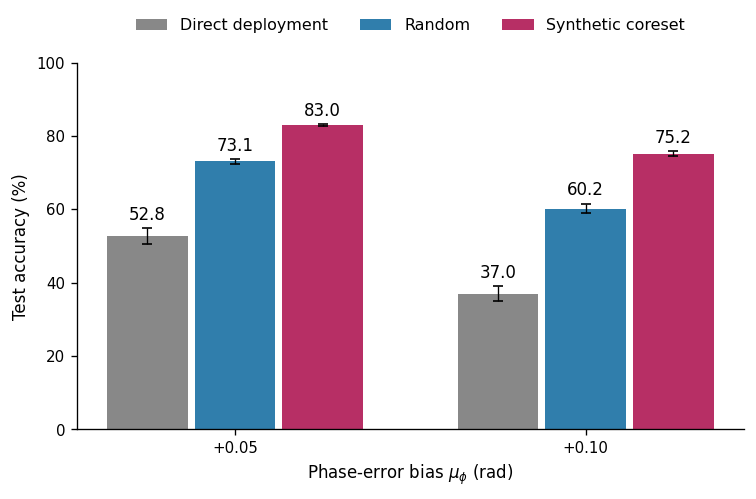

In [20]:
phase_bias_results = mismatch_results('phase_bias', [0.05, 0.1])
plot_mismatch(
    phase_bias_results, ["+0.05", "+0.10"], "Phase-error bias $\\mu_\\phi$ (rad)", "mzi_phase_bias"
)


### 6.2. Broader phase-error distribution — Supplementary Figure 9b

Keep zero-mean phase errors and increase their spread: $\delta\theta,\delta\phi\sim\mathcal{N}(0,\sigma_\phi^2)$, with $\sigma_\phi=0.075,0.10$ rad. Splitter errors and arm losses are unchanged.


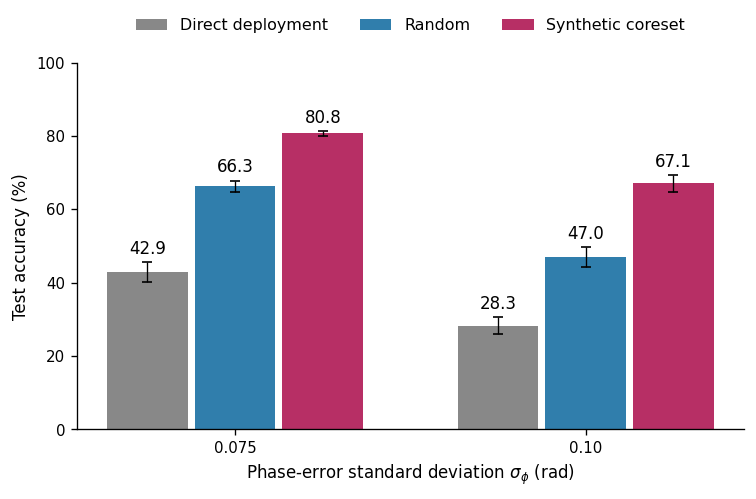

In [21]:
phase_sd_results = mismatch_results('phase_sd', [0.075, 0.1])
plot_mismatch(
    phase_sd_results,
    ["0.075", "0.10"],
    "Phase-error standard deviation $\\sigma_\\phi$ (rad)",
    "mzi_phase_sd",
)


### 6.3. Correlated splitter errors — Supplementary Figure 9c

For every splitter, $\delta_j=0.03(\sqrt{\rho}\,g+\sqrt{1-\rho}\,z_j)$ rad, with $g,z_j\sim\mathcal{N}(0,1)$ and $\rho=0.5,1$. The same $g$ is shared by all splitters in both layers of one device. Marginal standard deviation stays at $0.03$ rad; phase errors and arm losses are unchanged.


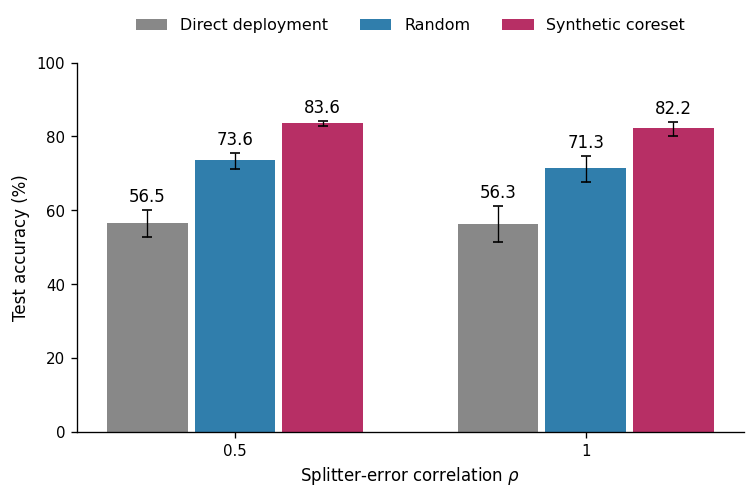

In [22]:
splitter_rho_results = mismatch_results('splitter_rho', [0.5, 1.0])
plot_mismatch(
    splitter_rho_results, ["0.5", "1"], "Splitter-error correlation $\\rho$", "mzi_splitter_rho"
)


### 6.4. Identical splitter offsets — Supplementary Figure 9d

Replace the random splitter errors by $\alpha=\beta=\mu_s$ at every splitter in both layers, with $\mu_s=0.03,0.05$ rad. Phase errors and arm losses retain their original distributions.


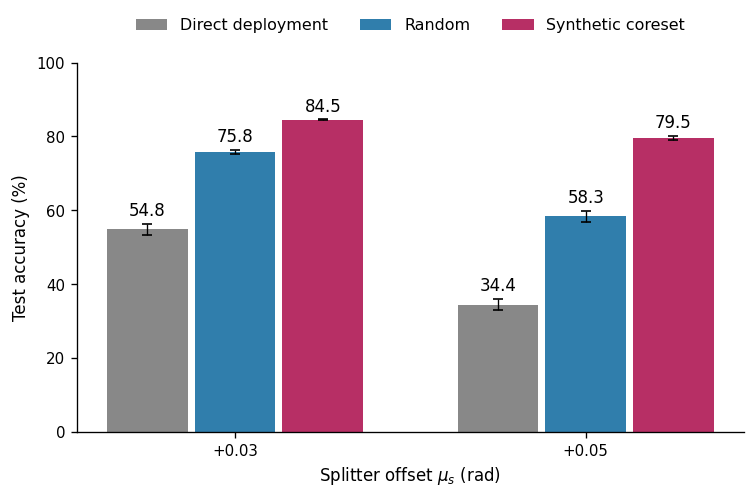

In [23]:
splitter_offset_results = mismatch_results('splitter_offset', [0.03, 0.05])
plot_mismatch(
    splitter_offset_results,
    ["+0.03", "+0.05"],
    "Splitter offset $\\mu_s$ (rad)",
    "mzi_splitter_offset",
)


## 7. Device-specific distillation and transfer — Supplementary Figure 4

Distill on one prespecified device (seed 2300000), using 40 or 80 synthetic
samples for four or eight PAT updates (batch size 10). Both runs optimize inputs,
targets and the update rule for 2,500 outer steps; four query batches share the
same fixed device. The source model, data split, error distribution and optimizer
settings match the ensemble experiment. The functions below share the same
training loop for both horizons and retain optimizer and random-generator state
for resuming a run.



In [24]:
DS_ROOT = ROOT
DS_DIRS = {
    8: DS_ROOT / "results/simulation/mzi/device_specific/K8",
    4: DS_ROOT / "results/simulation/mzi/device_specific/K4",
}
DS_CONFIG = copy.deepcopy(config)
DS_SOURCE = DS_ROOT / "results/simulation/mzi/source.pt"
DS_ENSEMBLE = DS_ROOT / "results/simulation/mzi/coreset.pt"
DS_ENSEMBLE_LAST = DS_ROOT / "results/simulation/mzi/coreset_last.pt"
DS_TARGET_SEED = 2300000
DS_DEVICE = DEVICE
assert DS_CONFIG["distillation"]["outer"] == 2500
lo, hi = DS_CONFIG["training_chip_pool"]
assert not lo <= DS_TARGET_SEED <= hi
assert DS_TARGET_SEED not in DS_CONFIG["validation_chips"] + DS_CONFIG["test_chips"]


def ds_context():
    dataset = split_fmnist_for_mzi(
        load_fmnist(DS_ROOT / "dataset", device=DS_DEVICE, download=False),
        seed=DS_CONFIG["split_seed"],
    )
    source, encoder, net = load_source(DS_SOURCE, DS_DEVICE)
    return dict(
        dataset=dataset,
        source=source,
        encoder=encoder,
        net=net,
        fields=[encoder.encode(x) for x, y in dataset],
    )


def ds_rule(ck):
    return dict(
        lr=ck["lr"], opt="sgd", precond=ck["pre"], momentum_schedule=ck["momentum_schedule"]
    )


def ds_detach_rule_checkpoint(ck):
    result = dict(ck)
    for key in ["u", "t", "lr", "momentum_schedule"]:
        result[key] = result[key].detach()
    result["pre"] = {k: v.detach() if torch.is_tensor(v) else v for k, v in ck["pre"].items()}
    return result


def ds_stats(values):
    v = np.asarray(values, dtype=float)
    result = dict(mean=float(v.mean()), per_device=v.tolist(), n_devices=len(v))
    if len(v) > 1:
        ix = np.random.default_rng(20261009).integers(0, len(v), (4000, len(v)))
        result.update(
            sd=float(v.std(ddof=1)), ci95=np.quantile(v[ix].mean(1), [0.025, 0.975]).tolist()
        )
    else:
        result.update(sd=None, ci95=None)
    return result


def ds_evaluate(ctx, ck, seeds, split="test", record_prefixes=False):
    assert ck["M"] == ck["B"] * ck["K"] and ck["B"] == 10
    horizon = ck["K"]
    ck = ds_detach_rule_checkpoint(ck)
    j = {"validation": 1, "test": 2}[split]
    fields, labels, net = ctx["fields"][j], ctx["dataset"][j][1], ctx["net"]
    checks = list(range(horizon + 1)) if record_prefixes else [horizon]
    curves = {str(k): [] for k in checks}
    for offset in range(0, len(seeds), DS_CONFIG["chip_batch"]):
        group = seeds[offset : offset + DS_CONFIG["chip_batch"]]
        chips = make_chips(group, net, DS_DEVICE, DS_CONFIG["errors"])
        state = expand_state(ctx["source"]["st"], len(group))

        def record(k, updated):
            if k in checks:
                values = 100 * accuracy(net, updated, fields, labels, chips)
                curves[str(k)].extend(values.cpu().tolist())

        record(0, state)
        out = adapt(
            net,
            state,
            cyclic_batches(ctx["encoder"].field(ck["u"]), ck["t"], 10, len(group)),
            chips,
            horizon,
            callback=record,
            **ds_rule(ck)
        )
        assert all(torch.isfinite(out[k]).all() for k in ["th", "ph"])
    return dict(
        **ds_stats(curves[str(horizon)]),
        curves=curves,
        seeds=list(seeds),
        split=split,
        n_images=len(labels),
        units="percent",
        M=ck["M"],
        B=ck["B"],
        K=horizon
    )


In [25]:
def ds_distill(ctx, K, folder=None, stop_after=None):
    assert K in (4, 8)
    folder = DS_DIRS[K] if folder is None else Path(folder)
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)
    cfg = copy.deepcopy(DS_CONFIG["distillation"])
    cfg.update(M=10 * K, B=10, K=K)
    limit = cfg["outer"] if stop_after is None else int(stop_after)
    assert 1 <= limit <= cfg["outer"]
    resume_path = folder / "coreset_resume.pt"
    torch.manual_seed(cfg["seed"])
    enc, net = ctx["encoder"], ctx["net"]
    x, y = ctx["dataset"][0]
    K, C = cfg["K"], cfg["chips_per_step"]
    ids = balanced_indices(y, cfg["M"] // 10, cfg["seed"]).view(10, -1).T.flatten()
    raw = dict(
        inputs=enc.u(x)[ids].detach().clone().requires_grad_(),
        targets=F.one_hot(y[ids], 10).float().requires_grad_(),
        log_lr=torch.full(
            (K, net.L, 1), math.log(cfg["inner_lr"]), device=DS_DEVICE, requires_grad=True
        ),
        log_theta=torch.zeros(K, net.L, net.geo.n, device=DS_DEVICE, requires_grad=True),
        log_phi=torch.zeros(K, net.L, net.geo.n, device=DS_DEVICE, requires_grad=True),
        raw_momentum=torch.full(
            (K,), math.log(0.5 / (0.99 - 0.5)), device=DS_DEVICE, requires_grad=True
        ),
    )
    optimizer = torch.optim.Adam(
        [
            dict(params=[raw["inputs"], raw["targets"]], lr=cfg["data_lr"]),
            dict(params=[raw["log_lr"], raw["log_theta"], raw["log_phi"]], lr=cfg["rule_lr"]),
            dict(params=[raw["raw_momentum"]], lr=cfg["momentum_lr"]),
        ]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, cfg["outer"])
    query_rng = torch.Generator(device=DS_DEVICE).manual_seed(cfg["seed"] + 200)
    target = make_chips([DS_TARGET_SEED], net, DS_DEVICE, DS_CONFIG["errors"])
    chips = {k: v.expand(C, *v.shape[1:]) for k, v in target.items()}
    save_checkpoint(
        folder / "target_device.pt",
        dict(
            seed=DS_TARGET_SEED, errors=DS_CONFIG["errors"], chip=target
        ),
    )
    save_json(
        folder / "protocol.json",
        dict(
            target_seed=DS_TARGET_SEED,
            errors=DS_CONFIG["errors"],
            distillation=cfg,
            query_streams=C,
            unique_training_devices=1,
            checkpoint_selection="Maximum validation accuracy on target device; earliest tie.",
            unseen_seeds=DS_CONFIG["test_chips"],
            target_selected_by_performance=False,
        ),
    )
    rows, start, best, elapsed_before = [], 0, -1.0, 0.0
    if flat_result_path(resume_path).exists():
        ck = torch.load(flat_result_path(resume_path), map_location=DS_DEVICE, weights_only=True)
        assert ck['config'] == cfg
        assert ck['target_seed'] == DS_TARGET_SEED
        for key, value in raw.items():
            with torch.no_grad():
                value.copy_(ck["raw_parameters"][key])
        optimizer.load_state_dict(ck["optimizer_state"])
        scheduler.load_state_dict(ck["scheduler_state"])
        query_rng.set_state(ck["query_rng_state"].cpu())
        rows, start, best = ck["rows"], ck["completed_outer"], ck["best_dev"]
        elapsed_before = ck["elapsed_seconds"]
        assert start <= limit
    began = time.monotonic()

    def checkpoint(it):
        return dict(
            dataset="FashionMNIST",
            u=raw["inputs"],
            t=raw["targets"],
            ids=ids,
            lr=raw["log_lr"].exp(),
            pre=dict(th=raw["log_theta"].exp(), ph=raw["log_phi"].exp(), _perstep=True),
            momentum_schedule=0.99 * raw["raw_momentum"].sigmoid(),
            M=cfg["M"],
            B=cfg["B"],
            K=K,
            opt="sgd",
            rule_kind="learned",
            config=cfg,
            target_seed=DS_TARGET_SEED,
            errors=DS_CONFIG["errors"],
            completed_outer=it,
            done=it == cfg["outer"],
            rows=list(rows),
            best_dev=best,
            raw_parameters=raw,
            optimizer_state=optimizer.state_dict(),
            scheduler_state=scheduler.state_dict(),
            query_rng_state=query_rng.get_state(),
            elapsed_seconds=elapsed_before + time.monotonic() - began,
        )

    for it in range(start, limit + 1):
        if (it % cfg["validation_interval"] == 0 or it == limit) and not any(
            r["it"] == it for r in rows
        ):
            val = ds_evaluate(ctx, checkpoint(it), [DS_TARGET_SEED], split="validation")
            score = val["mean"] / 100
            assert math.isfinite(score)
            rows.append(
                dict(
                    it=it,
                    target_validation_accuracy=val["mean"],
                    elapsed_seconds=elapsed_before + time.monotonic() - began,
                )
            )
            if score > best:
                best = score
                save_checkpoint(folder / "coreset_best.pt", checkpoint(it))
            save_json(folder / "history.json", dict(rows=rows, best_dev=best))
            save_checkpoint(resume_path, checkpoint(it))
        if it == limit:
            break
        state = adapt(
            net,
            expand_state(ctx["source"]["st"], C),
            cyclic_batches(enc.field(raw["inputs"]), raw["targets"], 10, C),
            chips,
            K,
            create_graph=True,
            **ds_rule(checkpoint(it)),
        )
        query = torch.randint(
            len(x), (C, cfg["query_batch"]), device=DS_DEVICE, generator=query_rng
        )
        loss = per_chip_ce(net.forward(state, ctx["fields"][0][query], chips), y[query]) / C
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite distillation objective")
        optimizer.zero_grad()
        loss.backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in raw.values())
        torch.nn.utils.clip_grad_norm_(list(raw.values()), 1.0)
        optimizer.step()
        scheduler.step()
        del state, query, loss
    save_checkpoint(resume_path, checkpoint(limit))
    save_checkpoint(folder / "coreset_last.pt", checkpoint(limit))
    return folder / "coreset_best.pt"


def ds_compare(ctx, K):
    folder = DS_DIRS[K]
    if K == 8:
        paths = dict(
            specific_selected=folder / "coreset_best.pt",
            specific_final=folder / "coreset_last.pt",
            ensemble_selected=DS_ENSEMBLE,
            ensemble_final=DS_ENSEMBLE_LAST,
        )
    else:
        paths = dict(
            specific4_selected=folder / "coreset_best.pt",
            specific4_final=folder / "coreset_last.pt",
            specific8_selected=DS_DIRS[8] / "coreset_best.pt",
            ensemble8_selected=DS_ENSEMBLE,
        )
    results = dict(protocol=json.loads((flat_result_path(folder / "protocol.json")).read_text()), conditions={})
    for name, path in paths.items():
        ck = torch.load(flat_result_path(path), map_location=DS_DEVICE, weights_only=True)
        assert ck["config"]["outer"] == 2500
        results["conditions"][name] = dict(
            checkpoint=str(flat_result_path(path).relative_to(DS_ROOT)),
            completed_outer=ck["completed_outer"],
            target=ds_evaluate(ctx, ck, [DS_TARGET_SEED], record_prefixes=True),
            unseen=ds_evaluate(ctx, ck, DS_CONFIG["test_chips"], record_prefixes=True),
        )
        save_json(folder / "results.json", results)
    results["paired_differences_pp"] = {}
    if K == 8:
        for selection in ["selected", "final"]:
            sp, en = (
                results["conditions"][f"{kind}_{selection}"] for kind in ["specific", "ensemble"]
            )
            results["paired_differences_pp"][selection] = dict(
                target_specific_minus_ensemble=sp["target"]["mean"] - en["target"]["mean"],
                unseen_specific_minus_ensemble=ds_stats(
                    np.asarray(sp["unseen"]["per_device"]) - np.asarray(en["unseen"]["per_device"])
                ),
            )
    else:
        new = results["conditions"]["specific4_selected"]
        for reference in ["specific8_selected", "ensemble8_selected"]:
            ref = results["conditions"][reference]
            results["paired_differences_pp"][reference] = dict(
                target_specific4_minus_reference_endpoint=new["target"]["mean"]
                - ref["target"]["mean"],
                target_specific4_minus_reference_prefix4=new["target"]["mean"]
                - ref["target"]["curves"]["4"][0],
                unseen_specific4_minus_reference_endpoint=ds_stats(
                    np.asarray(new["unseen"]["per_device"])
                    - np.asarray(ref["unseen"]["per_device"])
                ),
            )
    save_json(folder / "results.json", results)
    return results


In [26]:
ds_ctx = ds_context()
for K in [8, 4]:
    ds_distill(ds_ctx, K)
    ds_compare(ds_ctx, K)
device_results = {
    K: json.loads((flat_result_path(folder / "results.json")).read_text()) for K, folder in DS_DIRS.items()
}


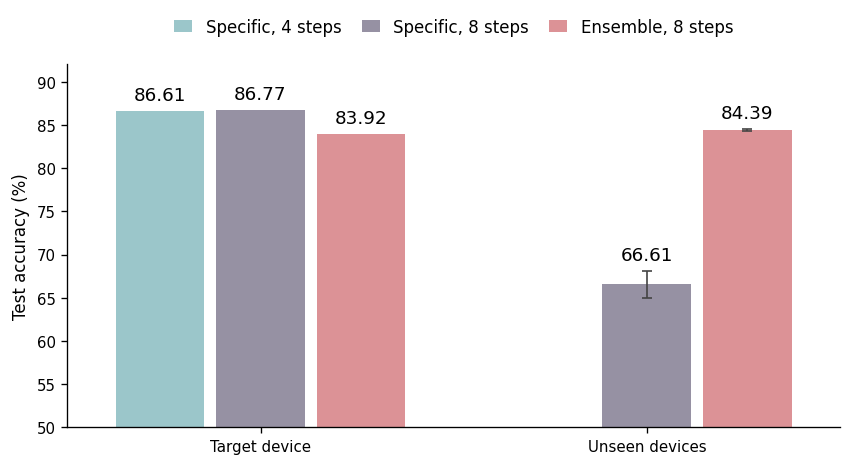

In [27]:
specific4 = device_results[4]["conditions"]["specific4_selected"]
specific8 = device_results[8]["conditions"]["specific_selected"]
ensemble8 = device_results[8]["conditions"]["ensemble_selected"]
fig, ax = plt.subplots(figsize=(7.2, 4.0))
for result, label, offset, color, cohorts in [
    (specific4, "Specific, 4 steps", -0.26, "#9bc6ca", ["target"]),
    (specific8, "Specific, 8 steps", 0.0, "#9691a3", ["target", "unseen"]),
    (ensemble8, "Ensemble, 8 steps", 0.26, "#dc9296", ["target", "unseen"]),
]:
    for i, cohort in enumerate(cohorts):
        record = result[cohort]
        mean, ci = record["mean"], record["ci95"]
        error = None if ci is None else np.array([[mean - ci[0]], [ci[1] - mean]])
        ax.bar(
            i + offset,
            mean,
            width=0.23,
            color=color,
            label=label if i == 0 else None,
            yerr=error,
            error_kw=dict(ecolor="#444444", capsize=3, lw=1),
        )
        ax.text(
            i + offset,
            mean + (0 if ci is None else ci[1] - mean) + 0.8,
            f"{mean:.2f}",
            ha="center",
            va="bottom",
            fontsize=11,
        )
ax.set(
    xticks=[0, 1],
    xticklabels=["Target device", "Unseen devices"],
    ylabel="Test accuracy (%)",
    ylim=(50, 92),
    xlim=(-0.5, 1.5),
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.17),
    ncol=3,
    frameon=False,
    fontsize=10,
    handlelength=1.1,
    columnspacing=1.2,
)
fig.tight_layout()
show_supplement(fig, "device_transfer")
